In [2]:
!pip install pillow chromadb open_clip_torch tqdm ipykernel

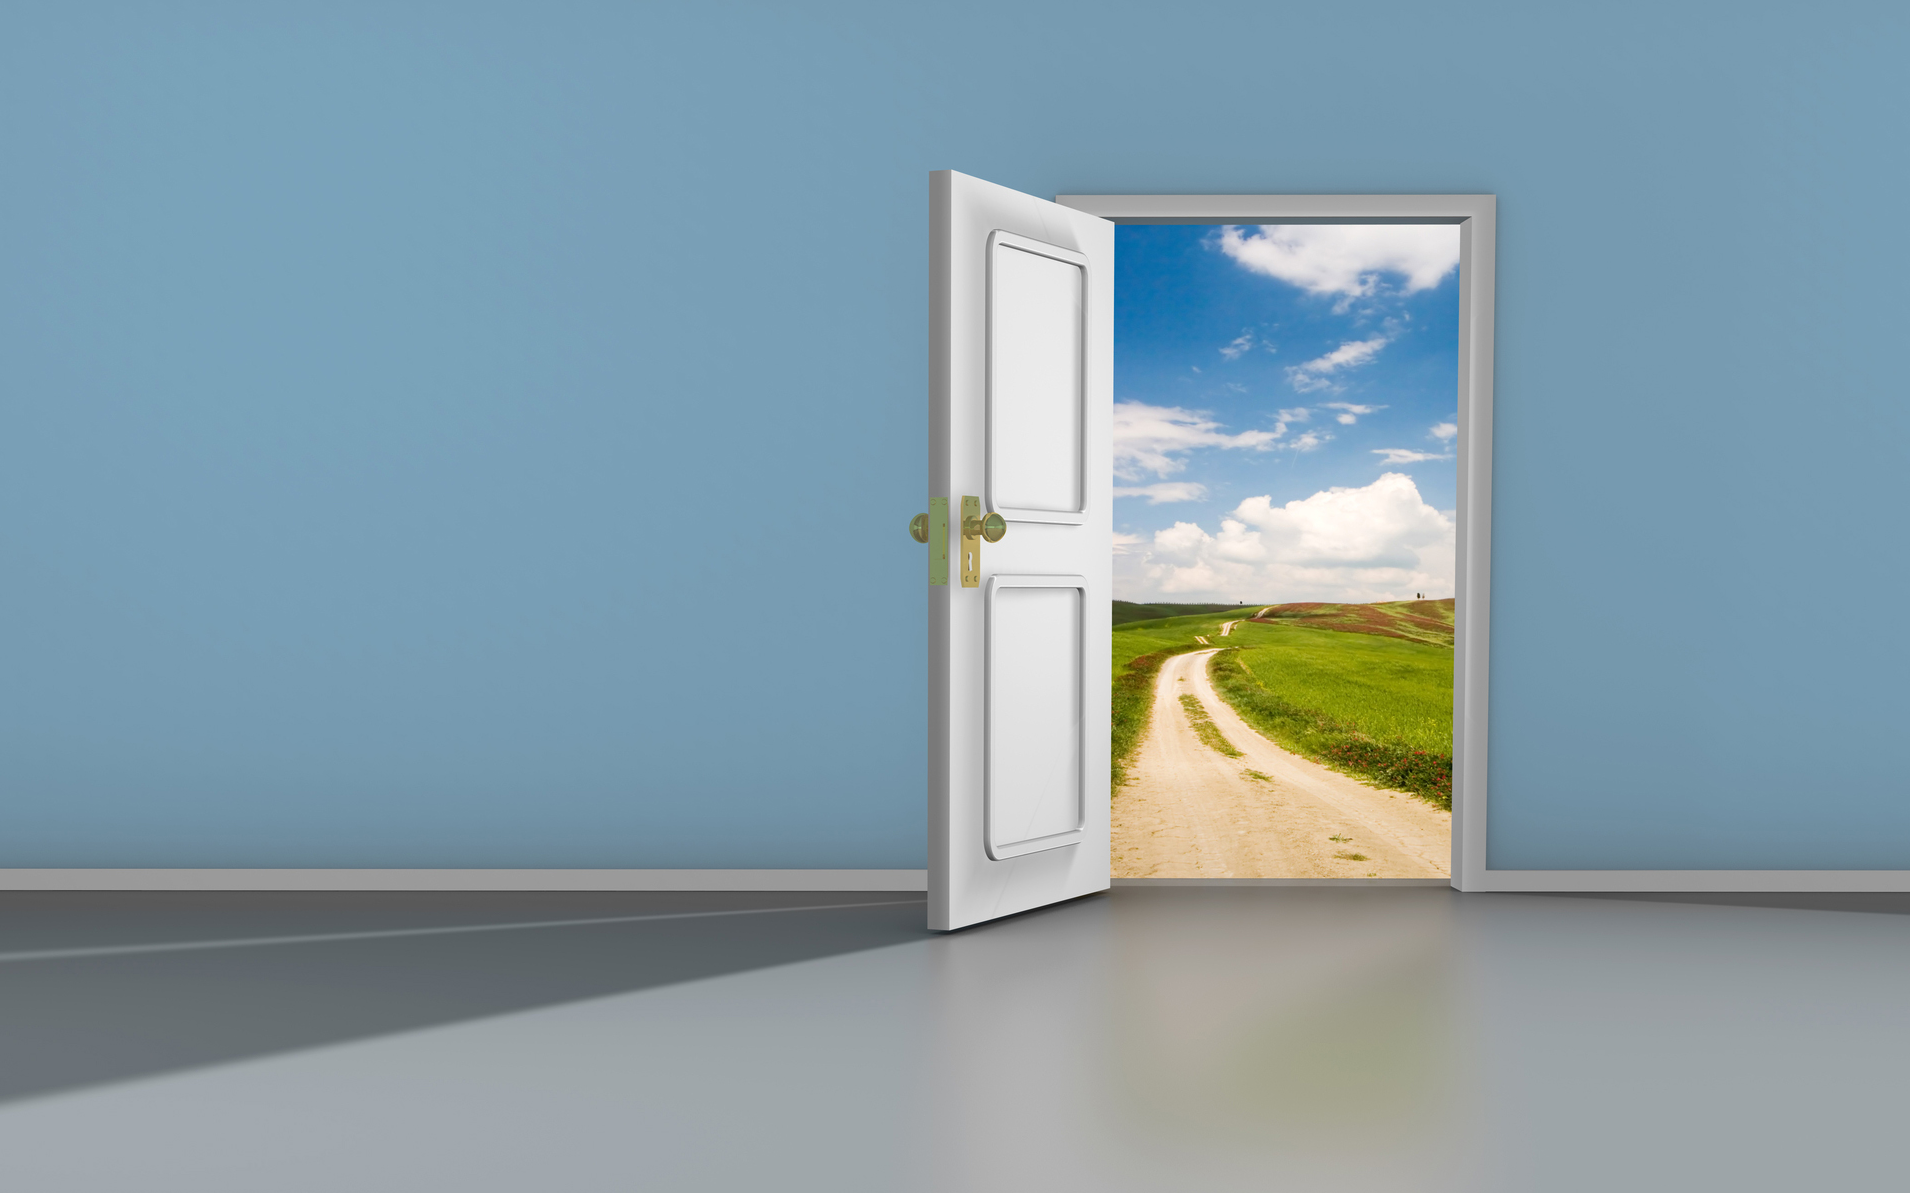

In [1]:
from PIL import Image
import glob

listeImages = []
for file_name in glob.glob("images/*.png"):
    image = Image.open(file_name)
    listeImages.append(image)

display(listeImages[1])

In [2]:
import chromadb
from chromadb.utils.data_loaders import ImageLoader
from chromadb.utils.embedding_functions import OpenCLIPEmbeddingFunction

BV_chromabd = chromadb.PersistentClient(path="db_storePortes")

chargeImages = ImageLoader()
VectorisationImages = OpenCLIPEmbeddingFunction()

chromadb = BV_chromabd.get_or_create_collection(
    name="portes_collection",
    data_loader=chargeImages,
    embedding_function=VectorisationImages
)


In [3]:
import os

indexImage = []
CheminImages = []
dossierImages = "images/"

for index, image_name in enumerate(sorted(os.listdir(dossierImages))):
    if image_name.endswith(".png"):
        image_path = os.path.join(dossierImages, image_name)
        indexImage.append(str(index))
        CheminImages.append(image_path)

print(indexImage[:21])
print(CheminImages[:21])

['0', '1']
['images/porte fermee.png', 'images/porte ouverte.png']


In [4]:
chromadb.add(ids=indexImage, uris=CheminImages)

In [5]:
chromadb.count()

2

In [8]:
rechercheParText = chromadb.query(
    query_texts=["  ouverte "],
    n_results=1,
    include=["uris", "distances"]
)

rechercheParText

{'ids': [['1']],
 'embeddings': None,
 'documents': None,
 'uris': [['images/porte ouverte.png']],
 'included': ['uris', 'distances'],
 'data': None,
 'metadatas': None,
 'distances': [[0.8131106495857239]]}

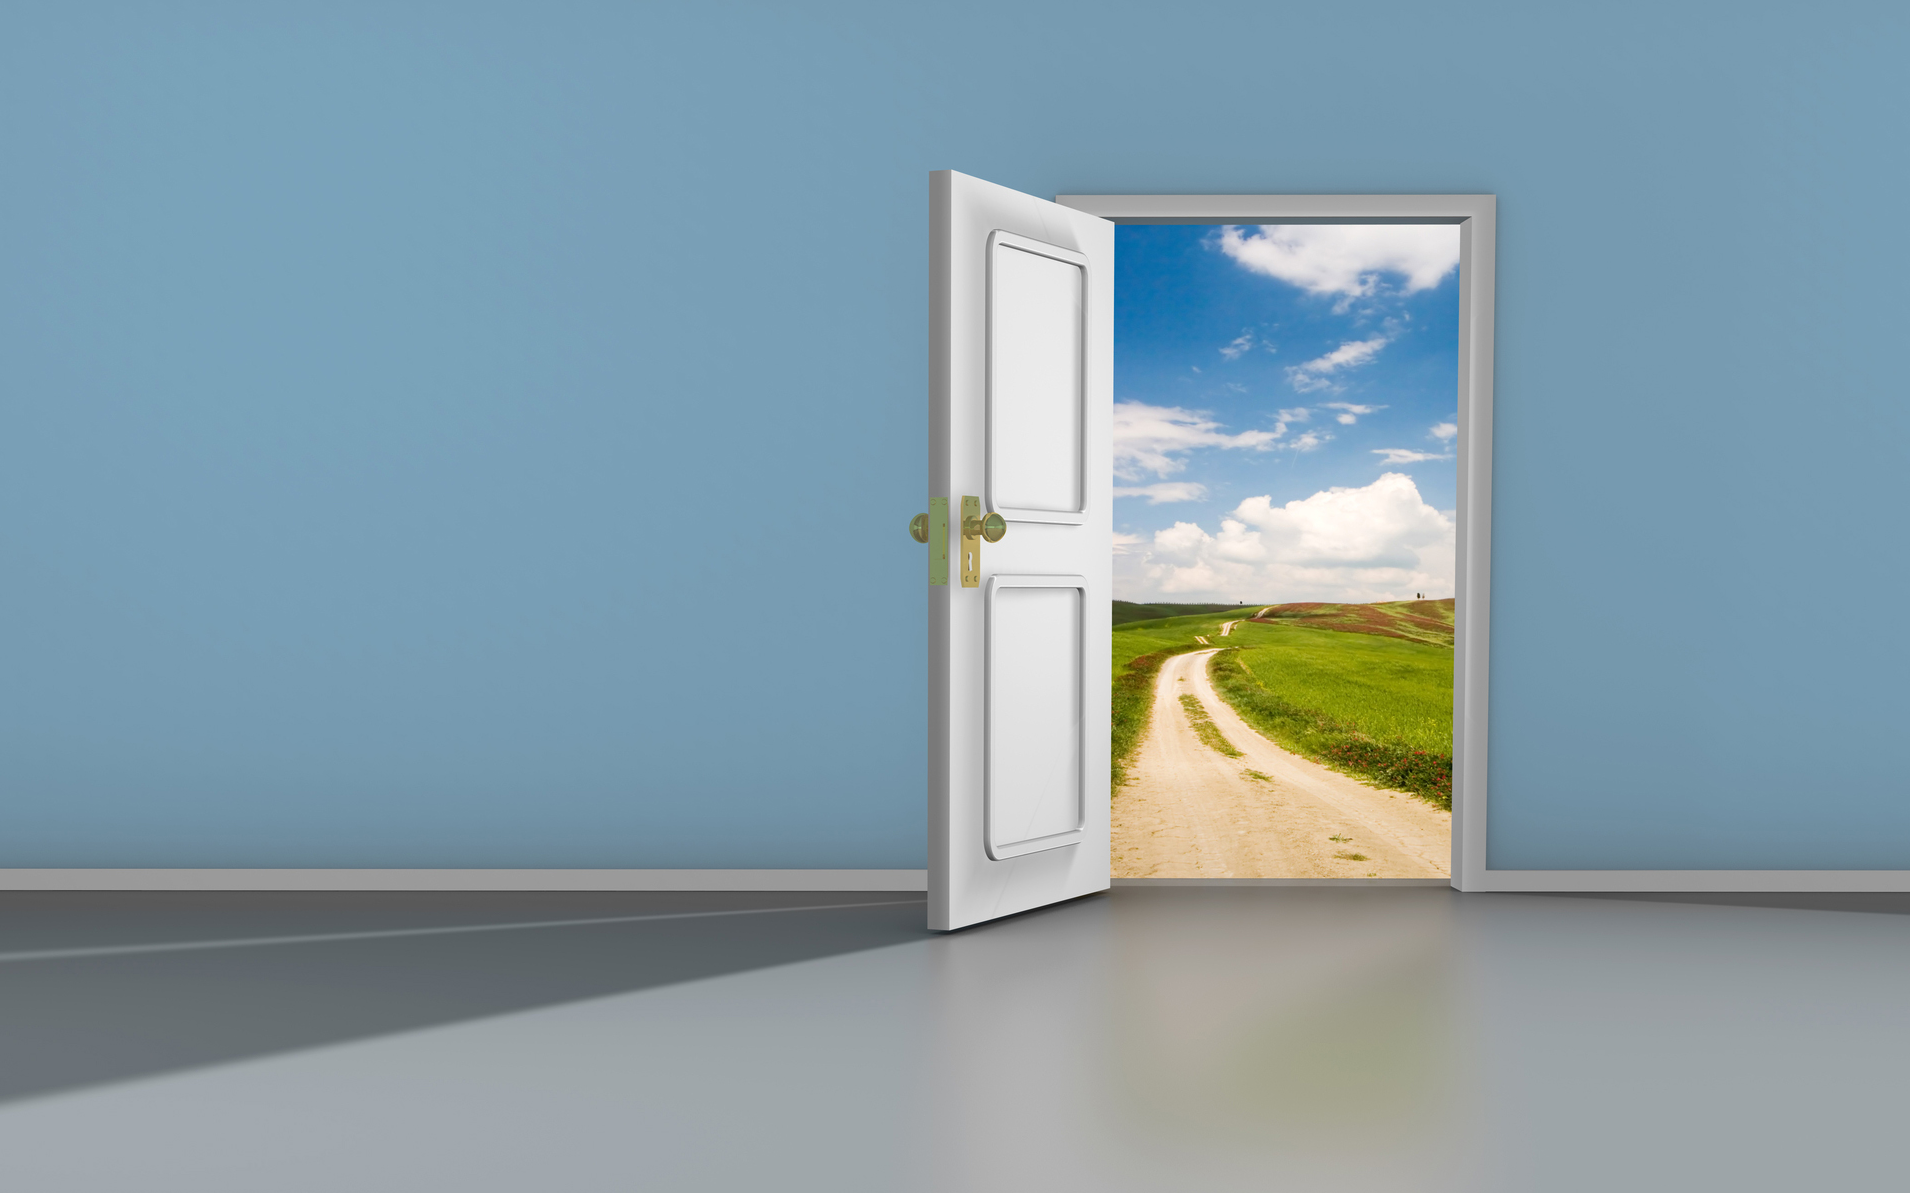

In [9]:
from PIL import Image  # importer Image
from IPython.display import display  # importer display si tu es dans un notebook

for image_path in rechercheParText["uris"][0]:
    display(Image.open(image_path))


In [10]:
import speech_recognition as sr
from PIL import Image 
from IPython.display import display 

# Initialisation du microphone
recognizer = sr.Recognizer()
microphone = sr.Microphone()

# Ajustement pour le bruit ambiant (optionnel, pour une meilleure précision)
with microphone as source:
    recognizer.adjust_for_ambient_noise(source)

print("Dites quelque chose... (Écoute pendant 5 secondes)")

# Capture de l'audio
with microphone as source:
    # Écoute pendant 5 secondes (ajustez timeout si besoin)
    audio = recognizer.listen(source, timeout=5)

print("Traitement de la voix...")

try:
    # Reconnaissance vocale avec Google (langue française par défaut)
    texte = recognizer.recognize_google(audio, language='fr-FR')
    print(f"Vous avez dit : {texte}")

    rechercheParText = chromadb.query(
    query_texts=[texte],
    n_results=1,
    include=["uris", "distances"]
)
    for image in rechercheParText["uris"][0]:
        display(Image.open(image))
except sr.UnknownValueError:
    print("Désolé, je n'ai pas compris ce que vous avez dit.")
except sr.RequestError as e:
    print(f"Erreur lors de la reconnaissance : {e}")

Dites quelque chose... (Écoute pendant 5 secondes)
Traitement de la voix...
Désolé, je n'ai pas compris ce que vous avez dit.


In [11]:
import smtplib
from email.mime.text import MIMEText
from email.mime.multipart import MIMEMultipart

# Configuration (remplacez par vos infos)
expediteur = "yangassojeanyves@gmail.com"  # Votre adresse email
mot_de_passe_app = "trcsvsynczjnawyc"      # Mot de passe d'application Google
destinataire = "myteacherit2@gmail.com"    # Email du destinataire
sujet = "Information porte"
corps = "Bonjour ! Une personne vient de sonner à la porte."

# Création du message
message = MIMEMultipart()
message["From"] = expediteur
message["To"] = destinataire
message["Subject"] = sujet
message.attach(MIMEText(corps, "plain"))

try:
    # Connexion au serveur SMTP (pour Gmail : smtp.gmail.com, port 587)
    serveur = smtplib.SMTP("smtp.gmail.com", 587)
    serveur.starttls()  # Activation du chiffrement TLS
    serveur.login(expediteur, mot_de_passe_app)  # Authentification
    
    # Convertir le message en chaîne
    texte_message = message.as_string()
    
    # Envoi de l'email
    serveur.sendmail(expediteur, destinataire, texte_message)
    serveur.quit()  # Fermeture de la connexion
    
    print("Email envoyé avec succès !")

except Exception as e:
    print(f"Erreur lors de l'envoi : {e}")


Email envoyé avec succès !


In [ ]:
from gtts import gTTS
import os
import tempfile

# Boucle principale pour interagir
while True:
    texte = input("Entrez du texte à lire (ou 'quit' pour arrêter) : ")
    if texte.lower() == 'quit':
        break
    
    # Génération du MP3 avec gTTS (français)
    tts = gTTS(text=texte, lang='fr')
    
    # Fichier temporaire
    with tempfile.NamedTemporaryFile(delete=False, suffix='.mp3') as tmp_file:
        nom_fichier = tmp_file.name
        tts.save(nom_fichier)
    
    # Lecture avec le lecteur par défaut (Windows : start)
    os.system(f'start "" "{nom_fichier}"')
    
    # Attendre un peu pour que ça se lance, puis nettoyer (optionnel, après fermeture manuelle)
    input("Appuyez sur Entrée quand la lecture est finie pour continuer... ")
    try:
        os.remove(nom_fichier)
    except:
        pass  # Si encore en cours, ignore
    
    print("Texte lu !")

print("Programme TTS arrêté.")

In [ ]:
import speech_recognition as sr
from PIL import Image
from IPython.display import display, clear_output
import ipywidgets as widgets
import smtplib
from email.mime.text import MIMEText
from email.mime.multipart import MIMEMultipart
from email.mime.base import MIMEBase
from email import encoders

# ======================================================
# CONFIG EMAIL
# ======================================================
expediteur = "yangassojeanyves@gmail.com"
mot_de_passe_app = "trcsvsynczjnawyc"
destinataire = "myteacherit2@gmail.com"

def envoyer_email(texte, chemin_image=None):
    sujet = "Résultat de la recherche"
    corps = f"Voici le résultat de votre recherche :\n\n{texte}"

    # Création du message
    message = MIMEMultipart()
    message["From"] = expediteur
    message["To"] = destinataire
    message["Subject"] = sujet
    message.attach(MIMEText(corps, "plain"))
 
    # Ajout de l’image si disponible
    if chemin_image:
        try:
            with open(chemin_image, "rb") as f:
                pj = MIMEBase("application", "octet-stream")
                pj.set_payload(f.read())
                encoders.encode_base64(pj)
                pj.add_header("Content-Disposition", f'attachment; filename="{chemin_image}"')
                message.attach(pj)
        except Exception as e:
            print(f"Erreur lors de l'ajout de l'image : {e}")

    try:
        serveur = smtplib.SMTP("smtp.gmail.com", 587)
        serveur.starttls()
        serveur.login(expediteur, mot_de_passe_app)
        serveur.sendmail(expediteur, destinataire, message.as_string())
        serveur.quit()
        print("📧 Email envoyé avec succès !")
    except Exception as e:
        print(f"Erreur lors de l'envoi de l'email : {e}")


# ======================================================
# Micro
# ======================================================
recognizer = sr.Recognizer()
microphone = sr.Microphone()

with microphone as source:
    recognizer.adjust_for_ambient_noise(source)

# ======================================================
# Widgets
# ======================================================
text_input = widgets.Text(
    value='',
    placeholder='Saisissez votre requête ici...',
    description='Texte:',
    layout=widgets.Layout(width='500px')
)

btn_text = widgets.Button(
    description='Rechercher par Texte',
    button_style='info',
    icon='search'
)

btn_voice = widgets.Button(
    description='Rechercher par Voix',
    button_style='success',
    icon='microphone'
)

output = widgets.Output()


# ======================================================
# Fonction de recherche améliorée
# ======================================================
def perform_search(texte):
    with output:
        clear_output(wait=True)
        print("Traitement de la requête...")

    try:
        result = chromadb.query(
            query_texts=[texte],
            n_results=1,
            include=["uris", "distances"]
        )

        with output:
            print(f"Vous avez dit/saisi : {texte}")

        if not result or not result.get("uris") or not result["uris"][0]:
            with output:
                print("Aucune image trouvée.")
            envoyer_email(f"Recherche : {texte}\nAucun résultat trouvé.")
            return

        image_path = result["uris"][0][0]

        # Affichage dans l'interface
        with output:
            display(Image.open(image_path))

        # Envoi mail avec image
        envoyer_email(texte, chemin_image=image_path)

    except Exception as e:
        with output:
            print(f"Erreur lors de la recherche : {e}")


# ======================================================
# Click bouton texte
# ======================================================
def on_text_click(b):
    texte = text_input.value.strip()
    if texte:
        perform_search(texte)
    else:
        with output:
            clear_output(wait=True)
            print("Veuillez saisir du texte.")

btn_text.on_click(on_text_click)


# ======================================================
# Click bouton voix
# ======================================================
def on_voice_click(b):
    with output:
        clear_output(wait=True)
        print("Parlez maintenant... (écoute 5 secondes)")

    try:
        with microphone as source:
            audio = recognizer.listen(source, timeout=5, phrase_time_limit=5)

        with output:
            print("Reconnaissance vocale en cours...")

        texte = recognizer.recognize_google(audio, language='fr-FR')
        perform_search(texte)

    except sr.WaitTimeoutError:
        with output:
            print("Temps écoulé : aucun son détecté.")
    except sr.UnknownValueError:
        with output:
            print("Désolé, je n'ai pas compris.")
    except sr.RequestError as e:
        with output:
            print(f"Erreur reconnaissance : {e}")
    except Exception as e:
        with output:
            print(f"Erreur inattendue : {e}")

btn_voice.on_click(on_voice_click)


# ======================================================
# Interface graphique
# ======================================================
interface = widgets.VBox([
    widgets.HTML("<h2>Recherche d'Images par Texte ou Voix</h2>"),
    text_input,
    widgets.HBox([btn_text, btn_voice]),
    output
])

display(interface)
